In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
#read in data and check validity
evals_df = pd.read_excel('../../data/CBDI3 All Evals for NSS.xlsx')
evals_df.head

<bound method NDFrame.head of       Child ID Gender Date of Birth Location - Sub Level 1 contract number  \
0        44879      F    2022-09-27              Southwest      contract 3   
1        47795      F    2020-12-23      Greater Nashville      contract 2   
2        54340      M    2021-06-22        First Tennessee      contract 1   
3        54344      F    2022-03-07    Southeast Tennessee      contract 1   
4        54515      M    2021-11-04          Memphis Delta      contract 3   
...        ...    ...           ...                    ...             ...   
23942  SP03287      F    2023-09-25          Memphis Delta      contract 3   
23943  SP03288      F    2021-05-18          South Central      contract 2   
23944  SP03289      F    2021-10-31          South Central      contract 2   
23945  SP03290      M    2020-03-25          Memphis Delta      contract 3   
23946  SP03291      M    2023-09-18      Greater Nashville      contract 2   

                      Program Lab

In [3]:
#dataframe test
evals_df


,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Adaptive 95% Confidence Interval,...,Code 1,Code 2,Code 3,Code 4,Code 5,Code 6,Code 7,Code 8,Code 9,Code 10
0,44879,F,2022-09-27,Southwest,contract 3,BDI-3 Eligibility Evaluation,7.0,85.0,16,77-97,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,47795,F,2020-12-23,Greater Nashville,contract 2,BDI-3 Eligibility Evaluation,16.0,88.0,21,82-96,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,54340,M,2021-06-22,First Tennessee,contract 1,BDI-3 Eligibility Evaluation,8.0,90.0,25,81-101,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,54344,F,2022-03-07,Southeast Tennessee,contract 1,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,54515,M,2021-11-04,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,5.0,75.0,5,68-88,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,SP03287,F,2023-09-25,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23943,SP03288,F,2021-05-18,South Central,contract 2,BDI-3 Eligibility Evaluation,25.0,115.0,84,107-121,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23944,SP03289,F,2021-10-31,South Central,contract 2,BDI-3 Eligibility Evaluation,21.0,103.0,58,96-110,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23945,SP03290,M,2020-03-25,Memphis Delta,contract 3,BDI-3 Annual Evaluation,16.0,88.0,21,82-96,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
#dropping code columns to start cleaning data
evals_df=evals_df.drop(columns=['Code 1','Code 2','Code 3','Code 4','Code 5','Code 6','Code 7','Code 8','Code 9','Code 10'])
evals_df

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Adaptive 95% Confidence Interval,...,Cognitive-Perception and Concepts RS,Cognitive-Perception and Concepts SS,Cognitive-Perception and Concepts PR,Cognitive-Perception and Concepts AE,Cognitive-Perception and Concepts RDI,Cognitive-Perception and Concepts CSS,Cognitive-Perception and Concepts CSS 90%,Cognitive-Perception and Concepts Z-Score,Cognitive-Perception and Concepts T-Score,Cognitive-Perception and Concepts NCE
0,44879,F,2022-09-27,Southwest,contract 3,BDI-3 Eligibility Evaluation,7.0,85.0,16,77-97,...,9.0,13.0,84,12,98/90,411.0,392 - 431,1,60.0,71
1,47795,F,2020-12-23,Greater Nashville,contract 2,BDI-3 Eligibility Evaluation,16.0,88.0,21,82-96,...,11.0,7.0,16,18,29/90,437.0,421 - 453,– 1.00,40.0,29
2,54340,M,2021-06-22,First Tennessee,contract 1,BDI-3 Eligibility Evaluation,8.0,90.0,25,81-101,...,10.0,7.0,16,15,37/90,426.0,408 - 444,– 1.00,40.0,29
3,54344,F,2022-03-07,Southeast Tennessee,contract 1,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,9.0,10.0,50,12,92/90,411.0,392 - 431,0,50.0,50
4,54515,M,2021-11-04,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,5.0,75.0,5,68-88,...,10.0,10.0,50,15,88/90,426.0,408 - 444,0,50.0,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,SP03287,F,2023-09-25,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,6.0,15.0,95,6,>99/90,378.0,365 - 391,1.67,67.0,85
23943,SP03288,F,2021-05-18,South Central,contract 2,BDI-3 Eligibility Evaluation,25.0,115.0,84,107-121,...,20.0,14.0,91,37,99/90,499.0,491 - 508,1.33,63.0,78
23944,SP03289,F,2021-10-31,South Central,contract 2,BDI-3 Eligibility Evaluation,21.0,103.0,58,96-110,...,13.0,10.0,50,25,89/90,464.0,450 - 479,0,50.0,50
23945,SP03290,M,2020-03-25,Memphis Delta,contract 3,BDI-3 Annual Evaluation,16.0,88.0,21,82-96,...,23.0,9.0,37,40,75/90,507.0,500 - 515,– 0.33,47.0,43


In [5]:
#column Check
evals_df.columns.tolist()


['Child ID',
 'Gender',
 'Date of Birth',
 'Location - Sub Level 1',
 'contract number',
 'Program Label',
 'Adaptive Sum of Scaled Scores',
 'Adaptive Developmental Quotient',
 'Adaptive Percentile Rank',
 'Adaptive 95% Confidence Interval',
 'Adaptive RDI',
 'Adaptive Z-Score',
 'Adaptive T-Score',
 'Adaptive NCE',
 'Social-Emotional Sum of Scaled Scores',
 'Social-Emotional Developmental Quotient',
 'Social-Emotional Percentile Rank',
 'Social-Emotional 95% Confidence Interval',
 'Social-Emotional RDI',
 'Social-Emotional Z-Score',
 'Social-Emotional T-Score',
 'Social-Emotional NCE',
 'Communication Sum of Scaled Scores',
 'Communication Developmental Quotient',
 'Communication Percentile Rank',
 'Communication 95% Confidence Interval',
 'Communication RDI',
 'Communication Z-Score',
 'Communication T-Score',
 'Communication NCE',
 'Motor Sum of Scaled Scores',
 'Motor Developmental Quotient',
 'Motor Percentile Rank',
 'Motor 95% Confidence Interval',
 'Motor RDI',
 'Motor Z-Score

In [6]:
#dropping duplicates
evals_unique = evals_df.drop_duplicates(keep='first')
evals_unique

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Adaptive 95% Confidence Interval,...,Cognitive-Perception and Concepts RS,Cognitive-Perception and Concepts SS,Cognitive-Perception and Concepts PR,Cognitive-Perception and Concepts AE,Cognitive-Perception and Concepts RDI,Cognitive-Perception and Concepts CSS,Cognitive-Perception and Concepts CSS 90%,Cognitive-Perception and Concepts Z-Score,Cognitive-Perception and Concepts T-Score,Cognitive-Perception and Concepts NCE
0,44879,F,2022-09-27,Southwest,contract 3,BDI-3 Eligibility Evaluation,7.0,85.0,16,77-97,...,9.0,13.0,84,12,98/90,411.0,392 - 431,1,60.0,71
1,47795,F,2020-12-23,Greater Nashville,contract 2,BDI-3 Eligibility Evaluation,16.0,88.0,21,82-96,...,11.0,7.0,16,18,29/90,437.0,421 - 453,– 1.00,40.0,29
2,54340,M,2021-06-22,First Tennessee,contract 1,BDI-3 Eligibility Evaluation,8.0,90.0,25,81-101,...,10.0,7.0,16,15,37/90,426.0,408 - 444,– 1.00,40.0,29
3,54344,F,2022-03-07,Southeast Tennessee,contract 1,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,9.0,10.0,50,12,92/90,411.0,392 - 431,0,50.0,50
4,54515,M,2021-11-04,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,5.0,75.0,5,68-88,...,10.0,10.0,50,15,88/90,426.0,408 - 444,0,50.0,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,SP03287,F,2023-09-25,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,13.0,115.0,84,103-123,...,6.0,15.0,95,6,>99/90,378.0,365 - 391,1.67,67.0,85
23943,SP03288,F,2021-05-18,South Central,contract 2,BDI-3 Eligibility Evaluation,25.0,115.0,84,107-121,...,20.0,14.0,91,37,99/90,499.0,491 - 508,1.33,63.0,78
23944,SP03289,F,2021-10-31,South Central,contract 2,BDI-3 Eligibility Evaluation,21.0,103.0,58,96-110,...,13.0,10.0,50,25,89/90,464.0,450 - 479,0,50.0,50
23945,SP03290,M,2020-03-25,Memphis Delta,contract 3,BDI-3 Annual Evaluation,16.0,88.0,21,82-96,...,23.0,9.0,37,40,75/90,507.0,500 - 515,– 0.33,47.0,43


In [7]:
evals_unique['Adaptive Sum of Scaled Scores'].describe()

count    19493.000000
mean        11.412712
std          5.822943
min          1.000000
25%          7.000000
50%         11.000000
75%         15.000000
max         36.000000
Name: Adaptive Sum of Scaled Scores, dtype: float64

In [8]:
#trim down dataframes

columns_to_keep = ['Child ID','Gender','Date of Birth','Location - Sub Level 1','contract number','Program Label',
    'Adaptive Sum of Scaled Scores','Adaptive Developmental Quotient', 'Adaptive Percentile Rank','Social-Emotional Sum of Scaled Scores',
    'Social-Emotional Developmental Quotient','Social-Emotional Percentile Rank','Communication Sum of Scaled Scores',
    'Communication Developmental Quotient','Communication Percentile Rank','Motor Sum of Scaled Scores','Motor Developmental Quotient',
    'Motor Percentile Rank','Cognitive Sum of Scaled Scores','Cognitive Developmental Quotient','Cognitive Percentile Rank','BDI-3 Total Sum of Scaled Scores',
    'BDI-3 Total Developmental Quotient','BDI-3 Total Percentile Rank','Adaptive-Self Care Examiner','Adaptive-Self Care Date of Testing',
    'Adaptive-Self Care SS','Adaptive-Self Care PR','Adaptive-Personal Responsibility Examiner','Adaptive-Personal Responsibility Date of Testing',
    'Adaptive-Personal Responsibility SS','Adaptive-Personal Responsibility PR','Social Emotional-Adult Interaction Examiner',
    'Social Emotional-Adult Interaction Date of Testing','Social Emotional-Adult Interaction SS','Social Emotional-Adult Interaction PR',
    'Social Emotional-Peer Interaction Examiner','Social Emotional-Peer Interaction Date of Testing','Social Emotional-Peer Interaction SS',
    'Social Emotional-Peer Interaction PR','Social Emotional-Self Concept / Social Role Examiner','Social Emotional-Self Concept / Social Role Date of Testing',
    'Social Emotional-Self Concept / Social Role SS','Social Emotional-Self Concept / Social Role PR','Communication-Receptive Communication Examiner',
    'Communication-Receptive Communication Date of Testing','Communication-Receptive Communication SS','Communication-Receptive Communication PR',
    'Communication-Expressive Communication Examiner','Communication-Expressive Communication Date of Testing','Communication-Expressive Communication SS',
    'Communication-Expressive Communication PR','Motor-Gross Motor Examiner','Motor-Gross Motor Date of Testing','Motor-Gross Motor SS','Motor-Gross Motor PR',
    'Motor-Fine Motor Examiner','Motor-Fine Motor Date of Testing','Motor-Fine Motor SS','Motor-Fine Motor PR',
    'Motor-Perceptual Motor Examiner','Motor-Perceptual Motor Date of Testing','Motor-Perceptual Motor SS','Motor-Perceptual Motor PR',
    'Cognitive-Attention and Memory Examiner','Cognitive-Attention and Memory Date of Testing','Cognitive-Attention and Memory SS',
    'Cognitive-Attention and Memory PR','Cognitive-Reasoning / Academic Skills Examiner','Cognitive-Reasoning / Academic Skills Date of Testing',
    'Cognitive-Reasoning / Academic Skills SS','Cognitive-Reasoning / Academic Skills PR','Cognitive-Perception and Concepts Examiner',
    'Cognitive-Perception and Concepts Date of Testing','Cognitive-Perception and Concepts SS','Cognitive-Perception and Concepts PR']

evals_unique = evals_unique[columns_to_keep]
evals_unique

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Social-Emotional Sum of Scaled Scores,...,Cognitive-Attention and Memory SS,Cognitive-Attention and Memory PR,Cognitive-Reasoning / Academic Skills Examiner,Cognitive-Reasoning / Academic Skills Date of Testing,Cognitive-Reasoning / Academic Skills SS,Cognitive-Reasoning / Academic Skills PR,Cognitive-Perception and Concepts Examiner,Cognitive-Perception and Concepts Date of Testing,Cognitive-Perception and Concepts SS,Cognitive-Perception and Concepts PR
0,44879,F,2022-09-27,Southwest,contract 3,BDI-3 Eligibility Evaluation,7.0,85.0,16,29.0,...,7.0,16,NaN,NaT,NaN,NaN,Kelly Bryan,2023-06-23,13.0,84
1,47795,F,2020-12-23,Greater Nashville,contract 2,BDI-3 Eligibility Evaluation,16.0,88.0,21,32.0,...,9.0,37,Patti Lyle,2023-03-21,14.0,91,Patti Lyle,2023-03-21,7.0,16
2,54340,M,2021-06-22,First Tennessee,contract 1,BDI-3 Eligibility Evaluation,8.0,90.0,25,17.0,...,8.0,25,NaN,NaT,NaN,NaN,Karen McMillion,2023-04-06,7.0,16
3,54344,F,2022-03-07,Southeast Tennessee,contract 1,BDI-3 Eligibility Evaluation,13.0,115.0,84,21.0,...,14.0,91,NaN,NaT,NaN,NaN,Jennifer Vines,2023-02-23,10.0,50
4,54515,M,2021-11-04,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,5.0,75.0,5,11.0,...,9.0,37,NaN,NaT,NaN,NaN,Ally Simmons,2023-02-24,10.0,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,SP03287,F,2023-09-25,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,13.0,115.0,84,25.0,...,9.0,37,NaN,NaT,NaN,NaN,Rachel Anderson,2023-11-15,15.0,95
23943,SP03288,F,2021-05-18,South Central,contract 2,BDI-3 Eligibility Evaluation,25.0,115.0,84,38.0,...,13.0,84,Joanna Jones,2023-11-13,14.0,91,Joanna Jones,2023-11-13,14.0,91
23944,SP03289,F,2021-10-31,South Central,contract 2,BDI-3 Eligibility Evaluation,21.0,103.0,58,31.0,...,10.0,50,Joanna Jones,2023-11-14,9.0,37,Joanna Jones,2023-11-14,10.0,50
23945,SP03290,M,2020-03-25,Memphis Delta,contract 3,BDI-3 Annual Evaluation,16.0,88.0,21,25.0,...,7.0,16,Lauryn Hartness,2023-10-26,8.0,25,Lauryn Hartness,2023-10-26,9.0,37


In [9]:
#isolate scaled score 
ss_columns = {
    'Adaptive': 'Adaptive Sum of Scaled Scores','Adaptive-Self Care': 'Adaptive-Self Care SS',
    'Adaptive-Personal Responsibility': 'Adaptive-Personal Responsibility SS', 'Social-Emotional': 'Social-Emotional Sum of Scaled Scores',
    'Social Emotional-Adult Interaction': 'Social Emotional-Adult Interaction SS',
    'Social Emotional-Peer Interaction': 'Social Emotional-Peer Interaction SS',
    'Social Emotional-Self Concept / Social Role': 'Social Emotional-Self Concept / Social Role SS',
    'Communication': 'Communication Sum of Scaled Scores','Communication-Receptive Communication': 'Communication-Receptive Communication SS',
    'Communication-Expressive Communication': 'Communication-Expressive Communication SS',
    'Motor': 'Motor Sum of Scaled Scores', 'Motor-Gross Motor': 'Motor-Gross Motor SS','Motor-Fine Motor': 'Motor-Fine Motor SS',
    'Motor-Perceptual Motor': 'Motor-Perceptual Motor SS','Cognitive': 'Cognitive Sum of Scaled Scores',
    'Cognitive-Attention and Memory': 'Cognitive-Attention and Memory SS',
    'Cognitive-Reasoning / Academic Skills': 'Cognitive-Reasoning / Academic Skills SS',
    'Cognitive-Perception and Concepts': 'Cognitive-Perception and Concepts SS','BDI-3 Total': 'BDI-3 Total Sum of Scaled Scores'}

ss_means = pd.DataFrame({
    subgroup: evals_unique[column].mean()
    for subgroup, column in ss_columns.items()
}, index=['Mean']).T

ss_means

,Mean
Adaptive,11.412712
Adaptive-Self Care,7.453832
Adaptive-Personal Responsibility,7.957826
Social-Emotional,22.381153
Social Emotional-Adult Interaction,10.452409
Social Emotional-Peer Interaction,7.834124
Social Emotional-Self Concept / Social Role,8.032793
Communication,13.201500
Communication-Receptive Communication,6.709110
Communication-Expressive Communication,6.493991


In [10]:
#separating group means and subgroups
ss_main = ss_means.loc[['Adaptive','Social-Emotional','Communication', 'Motor', 'Cognitive']]
ss_sub  = ss_means.drop(['Adaptive','Social-Emotional','Communication','Motor','Cognitive','BDI-3 Total'])

In [11]:
ss_main

,Mean
Adaptive,11.412712
Social-Emotional,22.381153
Communication,13.201500
Motor,22.655334
Cognitive,20.220933


In [12]:
ss_sub

,Mean
Adaptive-Self Care,7.453832
Adaptive-Personal Responsibility,7.957826
Social Emotional-Adult Interaction,10.452409
Social Emotional-Peer Interaction,7.834124
Social Emotional-Self Concept / Social Role,8.032793
Communication-Receptive Communication,6.709110
Communication-Expressive Communication,6.493991
Motor-Gross Motor,8.621568
Motor-Fine Motor,9.783430
Motor-Perceptual Motor,8.545417


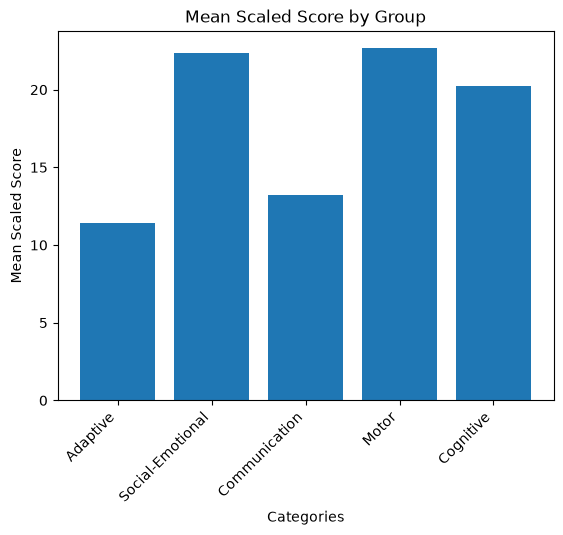

In [13]:
bars = ss_main.index
height = ss_main['Mean']
x_pos = range(len(bars))
plt.bar(x_pos, height)
plt.title('Mean Scaled Score by Group')
plt.xlabel('Categories')
plt.ylabel('Mean Scaled Score')
plt.xticks(x_pos, bars, rotation=45, ha='right')
plt.show()

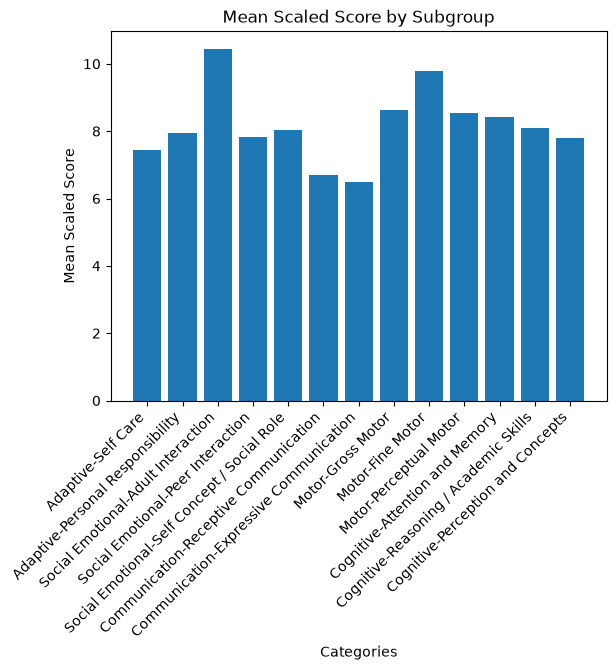

In [14]:
bars = ss_sub.index
height = ss_sub['Mean']
x_pos = range(len(bars))
plt.bar(x_pos, height)
plt.title('Mean Scaled Score by Subgroup')
plt.xlabel('Categories')
plt.ylabel('Mean Scaled Score')
plt.xticks(x_pos, bars, rotation=45, ha='right')
plt.show()

In [25]:
# Separate SS scores to investigate patterns

main_scores = ['Adaptive','Social-Emotional',
    'Communication','Motor','Cognitive']

ss_main_scores = evals_unique[
    [ss_columns[col] for col in main_scores]
]

ss_sub_scores = evals_unique[
    [col for key, col in ss_columns.items()
     if key not in main_scores + ['BDI-3 Total']]
]

In [26]:
ss_main_scores

,Adaptive Sum of Scaled Scores,Social-Emotional Sum of Scaled Scores,Communication Sum of Scaled Scores,Motor Sum of Scaled Scores,Cognitive Sum of Scaled Scores
0,7.0,29.0,17.0,16.0,20.0
1,16.0,32.0,19.0,31.0,30.0
2,8.0,17.0,14.0,23.0,15.0
3,13.0,21.0,16.0,17.0,24.0
4,5.0,11.0,10.0,11.0,19.0
...,...,...,...,...,...
23942,13.0,25.0,24.0,26.0,24.0
23943,25.0,38.0,24.0,38.0,41.0
23944,21.0,31.0,5.0,32.0,29.0
23945,16.0,25.0,12.0,30.0,24.0


In [27]:
ss_sub_scores

,Adaptive-Self Care SS,Adaptive-Personal Responsibility SS,Social Emotional-Adult Interaction SS,Social Emotional-Peer Interaction SS,Social Emotional-Self Concept / Social Role SS,Communication-Receptive Communication SS,Communication-Expressive Communication SS,Motor-Gross Motor SS,Motor-Fine Motor SS,Motor-Perceptual Motor SS,Cognitive-Attention and Memory SS,Cognitive-Reasoning / Academic Skills SS,Cognitive-Perception and Concepts SS
0,7.0,NaN,14.0,NaN,15.0,8.0,9.0,7.0,9.0,NaN,7.0,NaN,13.0
1,7.0,9.0,12.0,9.0,11.0,10.0,9.0,7.0,13.0,11.0,9.0,14.0,7.0
2,8.0,NaN,11.0,NaN,6.0,7.0,7.0,11.0,12.0,NaN,8.0,NaN,7.0
3,13.0,NaN,10.0,NaN,11.0,8.0,8.0,5.0,12.0,NaN,14.0,NaN,10.0
4,5.0,NaN,6.0,NaN,5.0,5.0,5.0,3.0,8.0,NaN,9.0,NaN,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,13.0,NaN,13.0,NaN,12.0,12.0,12.0,11.0,15.0,NaN,9.0,NaN,15.0
23943,10.0,15.0,12.0,13.0,13.0,14.0,10.0,15.0,11.0,12.0,13.0,14.0,14.0
23944,10.0,11.0,12.0,10.0,9.0,4.0,1.0,11.0,10.0,11.0,10.0,9.0,10.0
23945,6.0,10.0,8.0,11.0,6.0,7.0,5.0,9.0,10.0,11.0,7.0,8.0,9.0


In [28]:
# Convert dates to datetime
evals_unique['Date of Birth'] = pd.to_datetime(
    evals_unique['Date of Birth']
)

# Identify all testing date columns
testing_dates = [
    col for col in evals_unique.columns
    if col.endswith('Date of Testing')
]

# Calculate age at testing for each assessment
for col in testing_dates:
    eval_name = col.replace(' Date of Testing', '')

    evals_unique[f'{eval_name} Age (Months)'] = (
        evals_unique[col] - evals_unique['Date of Birth']
    ).dt.days / 30.4375

    evals_unique[f'{eval_name} Age (Years)'] = (
        evals_unique[col] - evals_unique['Date of Birth']
    ).dt.days / 365.25

In [29]:
evals_unique

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Social-Emotional Sum of Scaled Scores,...,Motor-Fine Motor Age (Months),Motor-Fine Motor Age (Years),Motor-Perceptual Motor Age (Months),Motor-Perceptual Motor Age (Years),Cognitive-Attention and Memory Age (Months),Cognitive-Attention and Memory Age (Years),Cognitive-Reasoning / Academic Skills Age (Months),Cognitive-Reasoning / Academic Skills Age (Years),Cognitive-Perception and Concepts Age (Months),Cognitive-Perception and Concepts Age (Years)
0,44879,F,2022-09-27,Southwest,contract 3,BDI-3 Eligibility Evaluation,7.0,85.0,16,29.0,...,8.837782,0.736482,NaN,NaN,8.837782,0.736482,NaN,NaN,8.837782,0.736482
1,47795,F,2020-12-23,Greater Nashville,contract 2,BDI-3 Eligibility Evaluation,16.0,88.0,21,32.0,...,26.874743,2.239562,26.874743,2.239562,26.874743,2.239562,26.874743,2.239562,26.874743,2.239562
2,54340,M,2021-06-22,First Tennessee,contract 1,BDI-3 Eligibility Evaluation,8.0,90.0,25,17.0,...,21.453799,1.787817,NaN,NaN,21.453799,1.787817,NaN,NaN,21.453799,1.787817
3,54344,F,2022-03-07,Southeast Tennessee,contract 1,BDI-3 Eligibility Evaluation,13.0,115.0,84,21.0,...,11.597536,0.966461,NaN,NaN,11.597536,0.966461,NaN,NaN,11.597536,0.966461
4,54515,M,2021-11-04,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,5.0,75.0,5,11.0,...,15.671458,1.305955,NaN,NaN,15.671458,1.305955,NaN,NaN,15.671458,1.305955
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,SP03287,F,2023-09-25,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,13.0,115.0,84,25.0,...,1.675565,0.139630,NaN,NaN,1.675565,0.139630,NaN,NaN,1.675565,0.139630
23943,SP03288,F,2021-05-18,South Central,contract 2,BDI-3 Eligibility Evaluation,25.0,115.0,84,38.0,...,29.864476,2.488706,29.864476,2.488706,29.864476,2.488706,29.864476,2.488706,29.864476,2.488706
23944,SP03289,F,2021-10-31,South Central,contract 2,BDI-3 Eligibility Evaluation,21.0,103.0,58,31.0,...,24.443532,2.036961,24.443532,2.036961,24.443532,2.036961,24.443532,2.036961,24.443532,2.036961
23945,SP03290,M,2020-03-25,Memphis Delta,contract 3,BDI-3 Annual Evaluation,16.0,88.0,21,25.0,...,43.039014,3.586585,43.039014,3.586585,43.039014,3.586585,43.039014,3.586585,43.039014,3.586585


In [32]:
#cleaning it up and converting to month only
for col in testing_dates:
    eval_name = col.replace(' Date of Testing', '')

    evals_unique[f'{eval_name} Age'] = (
        (evals_unique[col] - evals_unique['Date of Birth']).dt.days / 30.4375
    ).round(1)

In [33]:
evals_unique

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Social-Emotional Sum of Scaled Scores,...,Social Emotional-Peer Interaction Age,Social Emotional-Self Concept / Social Role Age,Communication-Receptive Communication Age,Communication-Expressive Communication Age,Motor-Gross Motor Age,Motor-Fine Motor Age,Motor-Perceptual Motor Age,Cognitive-Attention and Memory Age,Cognitive-Reasoning / Academic Skills Age,Cognitive-Perception and Concepts Age
0,44879,F,2022-09-27,Southwest,contract 3,BDI-3 Eligibility Evaluation,7.0,85.0,16,29.0,...,NaN,8.8,8.8,8.8,8.8,8.8,NaN,8.8,NaN,8.8
1,47795,F,2020-12-23,Greater Nashville,contract 2,BDI-3 Eligibility Evaluation,16.0,88.0,21,32.0,...,26.9,26.9,26.9,26.9,26.9,26.9,26.9,26.9,26.9,26.9
2,54340,M,2021-06-22,First Tennessee,contract 1,BDI-3 Eligibility Evaluation,8.0,90.0,25,17.0,...,NaN,21.5,21.5,21.5,21.5,21.5,NaN,21.5,NaN,21.5
3,54344,F,2022-03-07,Southeast Tennessee,contract 1,BDI-3 Eligibility Evaluation,13.0,115.0,84,21.0,...,NaN,11.6,11.6,11.6,11.6,11.6,NaN,11.6,NaN,11.6
4,54515,M,2021-11-04,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,5.0,75.0,5,11.0,...,NaN,15.7,15.7,15.7,15.7,15.7,NaN,15.7,NaN,15.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23942,SP03287,F,2023-09-25,Memphis Delta,contract 3,BDI-3 Eligibility Evaluation,13.0,115.0,84,25.0,...,NaN,1.7,1.7,1.7,1.7,1.7,NaN,1.7,NaN,1.7
23943,SP03288,F,2021-05-18,South Central,contract 2,BDI-3 Eligibility Evaluation,25.0,115.0,84,38.0,...,29.9,29.9,29.9,29.9,29.9,29.9,29.9,29.9,29.9,29.9
23944,SP03289,F,2021-10-31,South Central,contract 2,BDI-3 Eligibility Evaluation,21.0,103.0,58,31.0,...,24.4,24.4,24.4,24.4,24.4,24.4,24.4,24.4,24.4,24.4
23945,SP03290,M,2020-03-25,Memphis Delta,contract 3,BDI-3 Annual Evaluation,16.0,88.0,21,25.0,...,43.0,43.0,43.0,43.0,43.0,43.0,43.0,43.0,43.0,43.0


In [34]:
# Create 12-month intervals
max_age = evals_unique['Adaptive-Self Care Age'].max()

bins = np.arange(0, ((max_age // 12) + 2) * 12, 12)

labels = [
    f'{start}-{start + 11} months'
    for start in bins[:-1]
]

evals_unique['Age Group'] = pd.cut(
    evals_unique['Adaptive-Self Care Age'],
    bins=bins,
    labels=labels,
    right=False
)

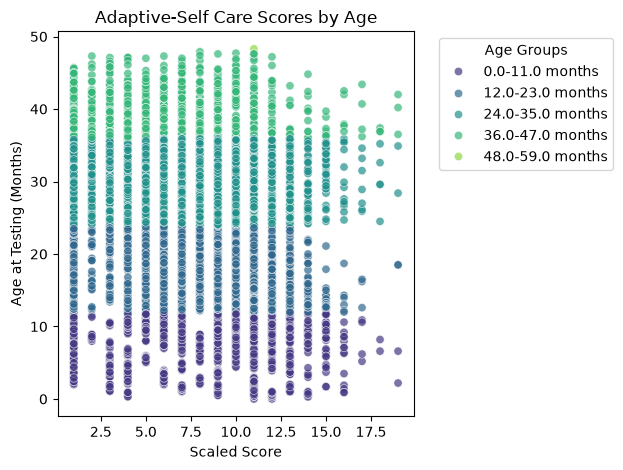

In [44]:
sns.scatterplot(
    data=evals_unique,
    y='Adaptive-Self Care Age',
    x='Adaptive-Self Care SS',
    hue='Age Group',
    palette='viridis',
    alpha=0.7
)

plt.title('Adaptive-Self Care Scores by Age')
plt.ylabel('Age at Testing (Months)')
plt.xlabel('Scaled Score')
plt.legend(title='Age Groups', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

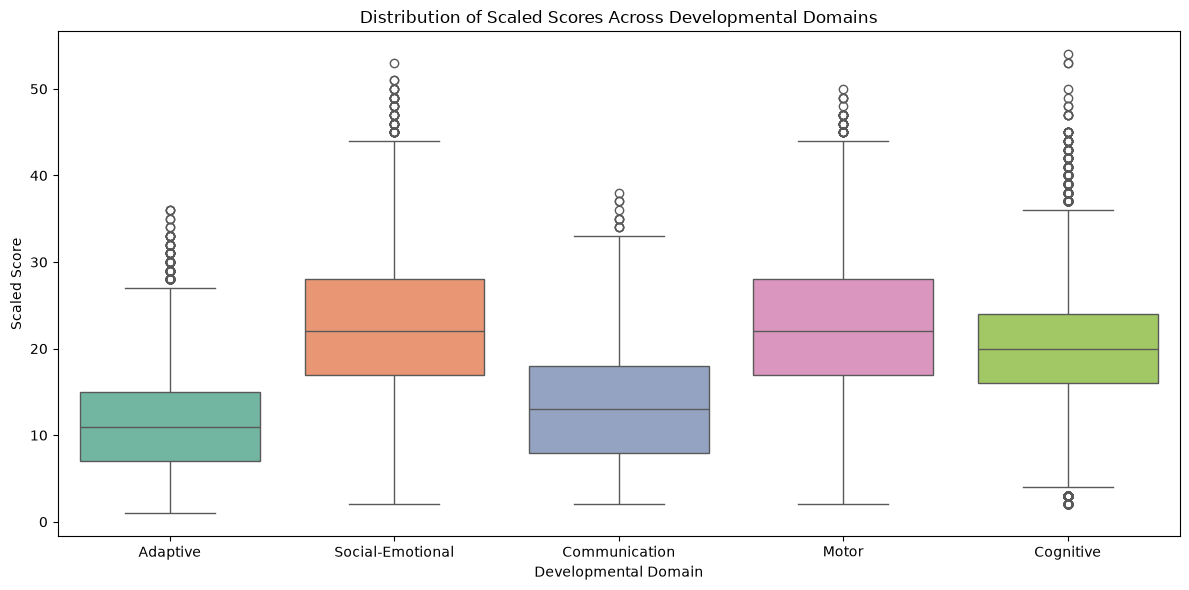

In [40]:
# Identify main developmental domains
main_domains = ['Adaptive','Social-Emotional','Communication','Motor','Cognitive']

# Create long-format dataset
domain_scores = evals_unique[[ss_columns[domain] for domain in main_domains]].copy()

domain_scores.columns = main_domains

domain_scores_long = domain_scores.melt(var_name='Domain',value_name='Scaled Score')

# Visualize score distributions
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=domain_scores_long,
    x='Domain',
    y='Scaled Score',
    hue='Domain',
    palette='Set2',
    legend=False)

plt.title('Distribution of Scaled Scores Across Developmental Domains')
plt.xlabel('Developmental Domain')
plt.ylabel('Scaled Score')
plt.tight_layout()
plt.show()

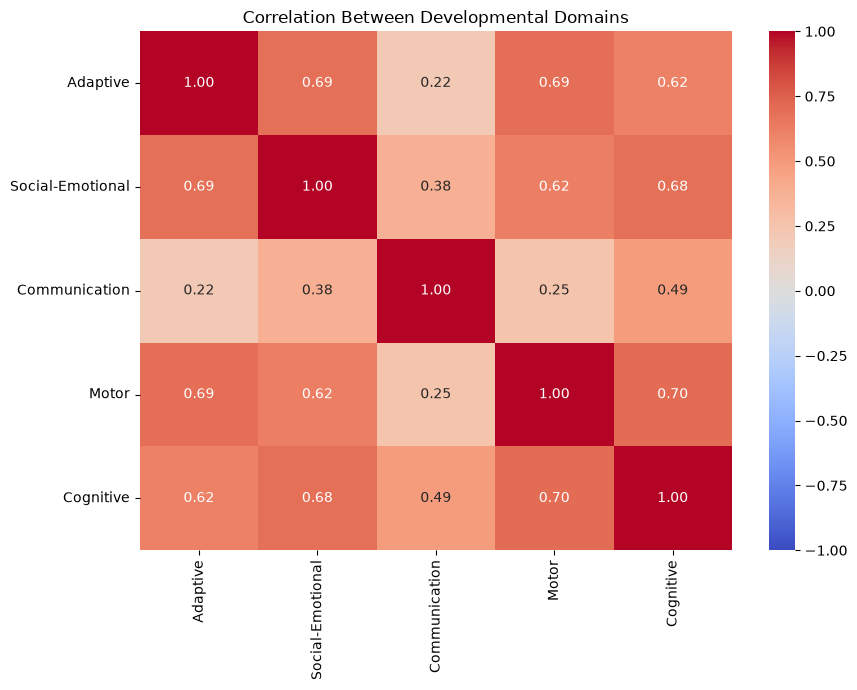

In [41]:
# Calculate domain correlations
domain_corr = domain_scores.corr(method='spearman')

plt.figure(figsize=(9, 7))

sns.heatmap(
    domain_corr,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.2f'
)

plt.title('Correlation Between Developmental Domains')
plt.tight_layout()
plt.show()

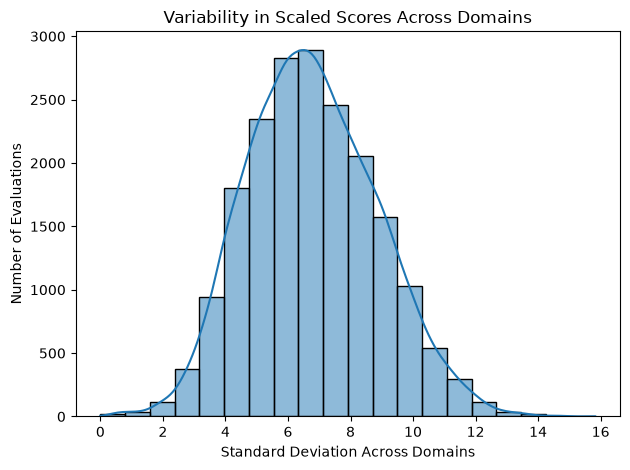

In [42]:
evals_unique['Domain Variability'] = domain_scores.std(axis=1)

sns.histplot(
    data=evals_unique,
    x='Domain Variability',
    bins=20,
    kde=True
)

plt.title('Variability in Scaled Scores Across Domains')
plt.xlabel('Standard Deviation Across Domains')
plt.ylabel('Number of Evaluations')
plt.tight_layout()
plt.show()

In [45]:
# Group subdomains by main domain
subdomain_groups = {'Adaptive': ['Adaptive-Self Care','Adaptive-Personal Responsibility'],
    'Social-Emotional': ['Social Emotional-Adult Interaction','Social Emotional-Peer Interaction',
    'Social Emotional-Self Concept / Social Role' ],
    'Communication': ['Communication-Receptive Communication','Communication-Expressive Communication'],
    'Motor': ['Motor-Gross Motor','Motor-Fine Motor','Motor-Perceptual Motor'],
    'Cognitive': ['Cognitive-Attention and Memory','Cognitive-Reasoning / Academic Skills','Cognitive-Perception and Concepts']}

In [58]:
highest = pd.Series(index=scores.index, dtype='object')
lowest = pd.Series(index=scores.index, dtype='object')

highest.loc[valid] = scores.loc[valid].idxmax(axis=1)
lowest.loc[valid] = scores.loc[valid].idxmin(axis=1)

discrepancy_df[f'{domain} Highest Subscale'] = highest.map( {ss_columns[sub]: sub for sub in subscales})

discrepancy_df[f'{domain} Lowest Subscale'] = lowest.map({ss_columns[sub]: sub for sub in subscales})

In [65]:
discrepancy_df = pd.DataFrame(index=evals_unique.index)

for domain, subscales in subdomain_groups.items():

    cols = [ss_columns[sub] for sub in subscales]
    scores = evals_unique[cols]

    valid = scores.notna().sum(axis=1) >= 2

    # Calculate maximum, minimum, and gap
    discrepancy_df[f'{domain} Max'] = scores.max(axis=1).where(valid)
    discrepancy_df[f'{domain} Min'] = scores.min(axis=1).where(valid)
    discrepancy_df[f'{domain} Gap'] = (
        scores.max(axis=1) - scores.min(axis=1)
    ).where(valid)

    # Identify highest and lowest subscales
    highest = pd.Series(index=scores.index, dtype='object')
    lowest = pd.Series(index=scores.index, dtype='object')

    highest.loc[valid] = scores.loc[valid].idxmax(axis=1)
    lowest.loc[valid] = scores.loc[valid].idxmin(axis=1)

    discrepancy_df[f'{domain} Highest Subscale'] = highest.map(
        {ss_columns[sub]: sub for sub in subscales}
    )

    discrepancy_df[f'{domain} Lowest Subscale'] = lowest.map(
        {ss_columns[sub]: sub for sub in subscales}
    )

    print(f'{domain}: Complete')

Adaptive: Complete
Social-Emotional: Complete
Communication: Complete
Motor: Complete
Cognitive: Complete


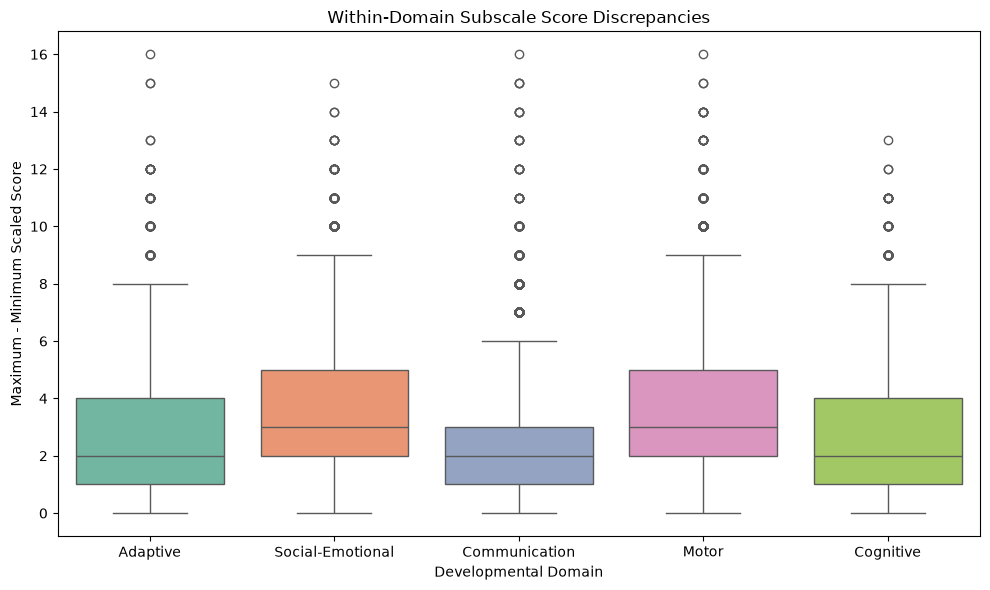

In [66]:
# Convert discrepancy gaps to long format
gap_data = discrepancy_df[
    [f'{domain} Gap' for domain in subdomain_groups]
].copy()

gap_data.columns = list(subdomain_groups.keys())

gap_long = gap_data.melt(
    var_name='Domain',
    value_name='Score Gap'
).dropna(subset=['Score Gap'])

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=gap_long,
    x='Domain',
    y='Score Gap',
    hue='Domain',
    palette='Set2',
    legend=False
)

plt.title('Within-Domain Subscale Score Discrepancies')
plt.xlabel('Developmental Domain')
plt.ylabel('Maximum - Minimum Scaled Score')
plt.tight_layout()
plt.show()

In [67]:
for domain in subdomain_groups:

    gap = discrepancy_df[f'{domain} Gap'].dropna()

    print(f'\n{domain}')
    print('Evaluations:', len(gap))
    print('Average gap:', round(gap.mean(), 2))
    print('Median gap:', gap.median())
    print('Evaluations with gap >= 3:',
          round((gap >= 3).mean() * 100, 2), '%')


Adaptive
Evaluations: 9697
Average gap: 2.72
Median gap: 2.0
Evaluations with gap >= 3: 46.35 %

Social-Emotional
Evaluations: 19487
Average gap: 3.43
Median gap: 3.0
Evaluations with gap >= 3: 61.72 %

Communication
Evaluations: 19469
Average gap: 2.12
Median gap: 2.0
Evaluations with gap >= 3: 34.64 %

Motor
Evaluations: 19478
Average gap: 3.3
Median gap: 3.0
Evaluations with gap >= 3: 57.83 %

Cognitive
Evaluations: 19481
Average gap: 2.72
Median gap: 2.0
Evaluations with gap >= 3: 49.44 %


In [68]:
for domain, subscales in subdomain_groups.items():

    cols = [ss_columns[sub] for sub in subscales]
    scores = evals_unique[cols]

    print(f'\n{domain}')
    print('Columns:', cols)
    print('Shape:', scores.shape)
    print('Valid evaluations:',
          (scores.notna().sum(axis=1) >= 2).sum())


Adaptive
Columns: ['Adaptive-Self Care SS', 'Adaptive-Personal Responsibility SS']
Shape: (19500, 2)
Valid evaluations: 9697

Social-Emotional
Columns: ['Social Emotional-Adult Interaction SS', 'Social Emotional-Peer Interaction SS', 'Social Emotional-Self Concept / Social Role SS']
Shape: (19500, 3)
Valid evaluations: 19487

Communication
Columns: ['Communication-Receptive Communication SS', 'Communication-Expressive Communication SS']
Shape: (19500, 2)
Valid evaluations: 19469

Motor
Columns: ['Motor-Gross Motor SS', 'Motor-Fine Motor SS', 'Motor-Perceptual Motor SS']
Shape: (19500, 3)
Valid evaluations: 19478

Cognitive
Columns: ['Cognitive-Attention and Memory SS', 'Cognitive-Reasoning / Academic Skills SS', 'Cognitive-Perception and Concepts SS']
Shape: (19500, 3)
Valid evaluations: 19481
